# Automobile Fuel Efficiency Analysis (1970-1982)
**Author:** Manish  
**Tools:** Python, Pandas, Matplotlib, Seaborn  
**Objective:** Analyze 398 cars to understand how weight, horsepower, cylinders and origin affect fuel efficiency, and how efficiency changed over time.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino


In [4]:
df.shape

(398, 9)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    str    
 8   name          398 non-null    str    
dtypes: float64(4), int64(3), str(2)
memory usage: 28.1 KB


In [6]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

In [7]:
df.describe()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


## 1. Data Cleaning & Preparation

In [8]:
df[df["horsepower"].isnull()]

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
32,25.0,4,98.0,NaN,2046,19.0,71,usa,ford pinto
126,21.0,6,200.0,NaN,2875,17.0,74,usa,ford maverick
330,40.9,4,85.0,NaN,1835,17.3,80,europe,renault lecar deluxe
336,23.6,4,140.0,NaN,2905,14.3,80,usa,ford mustang cobra
354,34.5,4,100.0,NaN,2320,15.8,81,europe,renault 18i
374,23.0,4,151.0,NaN,3035,20.5,82,usa,amc concord dl


In [9]:
df["horsepower"] = df["horsepower"].fillna(
    df.groupby("cylinders")["horsepower"].transform("median")
)

In [10]:
df.isnull().sum()

mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["origin"].value_counts()

origin
usa       249
japan      79
europe     70
Name: count, dtype: int64

In [13]:
df["cylinders"].value_counts().sort_index()

cylinders
3      4
4    204
5      3
6     84
8    103
Name: count, dtype: int64

## 2. Feature Engineering

In [14]:
df["year"] = df["model_year"] + 1900

In [15]:
df["origin"] = df["origin"].replace({"usa": "USA", "japan": "Japan", "europe": "Europe"})

In [16]:
df["brand"] = df["name"].str.split().str[0]

In [17]:
sorted(df["brand"].unique())

['amc',
 'audi',
 'bmw',
 'buick',
 'cadillac',
 'capri',
 'chevroelt',
 'chevrolet',
 'chevy',
 'chrysler',
 'datsun',
 'dodge',
 'fiat',
 'ford',
 'hi',
 'honda',
 'maxda',
 'mazda',
 'mercedes',
 'mercedes-benz',
 'mercury',
 'nissan',
 'oldsmobile',
 'opel',
 'peugeot',
 'plymouth',
 'pontiac',
 'renault',
 'saab',
 'subaru',
 'toyota',
 'toyouta',
 'triumph',
 'vokswagen',
 'volkswagen',
 'volvo',
 'vw']

In [18]:
df["brand"] = df["brand"].replace({
    "chevy": "chevrolet",
    "chevroelt": "chevrolet",
    "vw": "volkswagen",
    "vokswagen": "volkswagen",
    "toyouta": "toyota",
    "maxda": "mazda",
    "mercedes-benz": "mercedes"
})

In [19]:
df["mpg_category"] = pd.cut(
    df["mpg"],
    bins=[0, 20, 30, 50],
    labels=["Low (<20)", "Medium (20-30)", "High (>30)"]
)

In [20]:
df["kmpl"] = (df["mpg"] * 0.425).round(2)

In [21]:
df.head()

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name,year,brand,mpg_category,kmpl
0,18.0,8,307.0,130.0,3504,12.0,70,USA,chevrolet chevelle malibu,1970,chevrolet,Low (<20),7.65
1,15.0,8,350.0,165.0,3693,11.5,70,USA,buick skylark 320,1970,buick,Low (<20),6.38
2,18.0,8,318.0,150.0,3436,11.0,70,USA,plymouth satellite,1970,plymouth,Low (<20),7.65
3,16.0,8,304.0,150.0,3433,12.0,70,USA,amc rebel sst,1970,amc,Low (<20),6.80
4,17.0,8,302.0,140.0,3449,10.5,70,USA,ford torino,1970,ford,Low (<20),7.22


In [22]:
df["mpg_category"].value_counts()

mpg_category
Low (<20)         160
Medium (20-30)    153
High (>30)         85
Name: count, dtype: int64

In [23]:
df["brand"].nunique()

30

In [24]:
df["brand"].value_counts().head(10)

brand
ford          51
chevrolet     47
plymouth      31
amc           28
dodge         28
toyota        26
datsun        23
volkswagen    22
buick         17
pontiac       16
Name: count, dtype: int64

## 3. Exploratory Data Analysis

## Question 1: Kya fuel efficiency saalon me improve hui?

In [25]:
df.groupby("year")["mpg"].mean().round(2)

year
1970    17.69
1971    21.25
1972    18.71
1973    17.10
1974    22.70
1975    20.27
1976    21.57
1977    23.38
1978    24.06
1979    25.09
1980    33.70
1981    30.33
1982    31.71
Name: mpg, dtype: float64

## Question 2: Kaun sa region sabse fuel-efficient hai?

In [26]:
df.groupby("origin")["mpg"].agg(["mean", "median", "count"]).round(2)

,mean,median,count
origin,,,
Europe,27.89,26.5,70
Japan,30.45,31.6,79
USA,20.08,18.5,249


In [27]:
df.groupby("origin")[["mpg", "weight", "horsepower"]].mean().round(1)

,mpg,weight,horsepower
origin,,,
Europe,27.9,2423.3,80.5
Japan,30.5,2221.2,79.8
USA,20.1,3361.9,118.5


## Question 3: Weight aur horsepower mileage ko kaise affect karte hain?

In [28]:
df[["mpg", "weight", "horsepower", "displacement", "acceleration", "cylinders"]].corr().round(2)

,mpg,weight,horsepower,displacement,acceleration,cylinders
mpg,1.00,-0.83,-0.78,-0.80,0.42,-0.78
weight,-0.83,1.00,0.86,0.93,-0.42,0.90
horsepower,-0.78,0.86,1.00,0.90,-0.69,0.84
displacement,-0.80,0.93,0.90,1.00,-0.54,0.95
acceleration,0.42,-0.42,-0.69,-0.54,1.00,-0.51
cylinders,-0.78,0.90,0.84,0.95,-0.51,1.00


## Question 4: Cylinders mileage ko kaise badalte hain?

In [29]:
df.groupby("cylinders")["mpg"].agg(["mean", "count"]).round(2)

,mean,count
cylinders,,
3,20.55,4
4,29.29,204
5,27.37,3
6,19.99,84
8,14.96,103


## Question 5: Top 10 sabse fuel-efficient cars

In [30]:
df.nlargest(10, "mpg")[["name", "year", "origin", "mpg", "kmpl"]]

,name,year,origin,mpg,kmpl
322,mazda glc,1980,Japan,46.6,19.80
329,honda civic 1500 gl,1980,Japan,44.6,18.96
325,vw rabbit c (diesel),1980,Europe,44.3,18.83
394,vw pickup,1982,Europe,44.0,18.70
326,vw dasher (diesel),1980,Europe,43.4,18.44
244,volkswagen rabbit custom diesel,1978,Europe,43.1,18.32
309,vw rabbit,1980,Europe,41.5,17.64
330,renault lecar deluxe,1980,Europe,40.9,17.38
324,datsun 210,1980,Japan,40.8,17.34
247,datsun b210 gx,1978,Japan,39.4,16.74


In [31]:
df.nsmallest(5, "mpg")[["name", "year", "origin", "mpg", "kmpl"]]

,name,year,origin,mpg,kmpl
28,hi 1200d,1970,USA,9.0,3.82
25,ford f250,1970,USA,10.0,4.25
26,chevy c20,1970,USA,10.0,4.25
27,dodge d200,1970,USA,11.0,4.68
67,mercury marquis,1972,USA,11.0,4.68


## 4. Data Visualization

In [32]:
df["year"].value_counts().sort_index()

year
1970    29
1971    28
1972    28
1973    40
1974    27
1975    30
1976    34
1977    28
1978    36
1979    29
1980    29
1981    29
1982    31
Name: count, dtype: int64

In [33]:
pd.crosstab(df["year"], df["origin"])

origin,Europe,Japan,USA
year,,,
1970,5,2,22
1971,4,4,20
1972,5,5,18
1973,7,4,29
1974,6,6,15
1975,6,4,20
1976,8,4,22
1977,4,6,18
1978,6,8,22


In [34]:
os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

## Chart 1: Fuel efficiency trend (line chart)

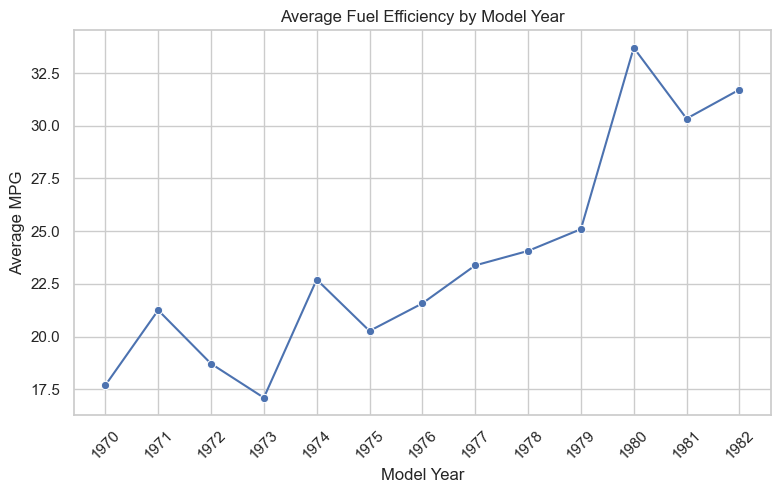

In [35]:
yearly_mpg = df.groupby("year")["mpg"].mean().reset_index()

plt.figure(figsize=(9, 5))
sns.lineplot(data=yearly_mpg, x="year", y="mpg", marker="o", color="#4C72B0")
plt.title("Average Fuel Efficiency by Model Year")
plt.xlabel("Model Year")
plt.ylabel("Average MPG")
plt.xticks(yearly_mpg["year"], rotation=45)
plt.savefig("images/01_mpg_trend_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 2: Mileage by region (boxplot)

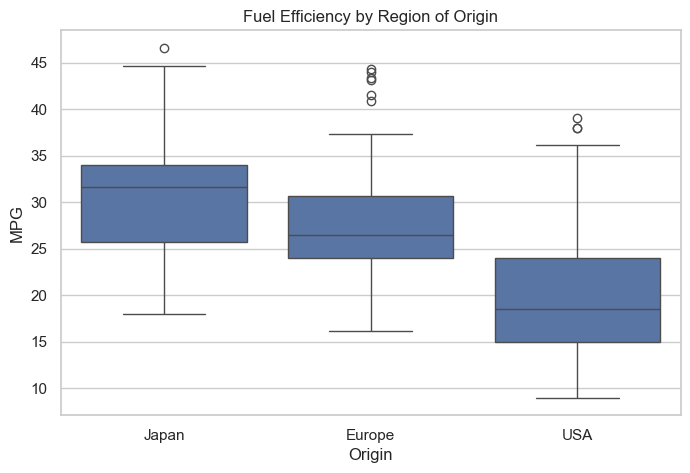

In [36]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="origin", y="mpg", order=["Japan", "Europe", "USA"], color="#4C72B0")
plt.title("Fuel Efficiency by Region of Origin")
plt.xlabel("Origin")
plt.ylabel("MPG")
plt.savefig("images/02_mpg_by_origin.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 3: Weight vs mileage (scatter plot)

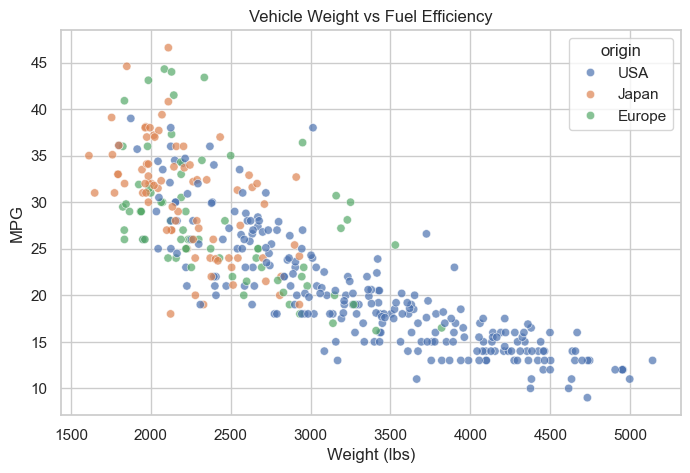

In [37]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="weight", y="mpg", hue="origin", alpha=0.7)
plt.title("Vehicle Weight vs Fuel Efficiency")
plt.xlabel("Weight (lbs)")
plt.ylabel("MPG")
plt.savefig("images/03_weight_vs_mpg.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 4: Correlation heatmap

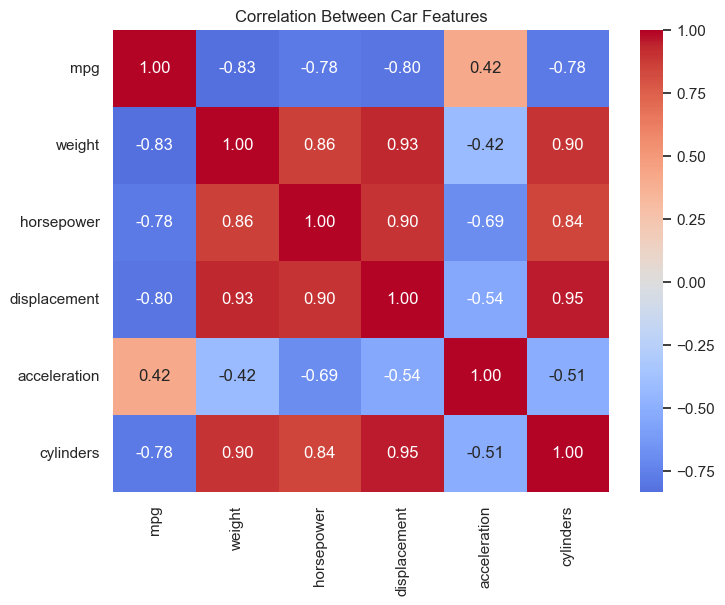

In [38]:
corr = df[["mpg", "weight", "horsepower", "displacement", "acceleration", "cylinders"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Car Features")
plt.savefig("images/04_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Chart 5: Mileage by number of cylinders (bar chart)

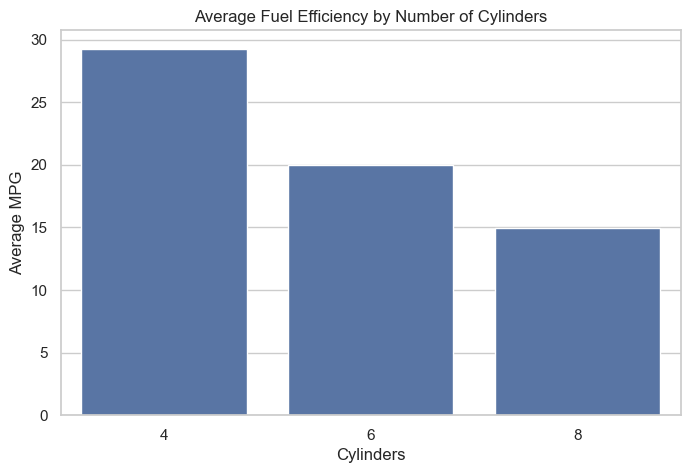

In [39]:
df_cyl = df[df["cylinders"].isin([4, 6, 8])]

plt.figure(figsize=(8, 5))
sns.barplot(data=df_cyl, x="cylinders", y="mpg", errorbar=None, color="#4C72B0")
plt.title("Average Fuel Efficiency by Number of Cylinders")
plt.xlabel("Cylinders")
plt.ylabel("Average MPG")
plt.savefig("images/05_mpg_by_cylinders.png", dpi=150, bbox_inches="tight")
plt.show()

In [40]:
df[df["origin"] == "USA"].groupby("year")["mpg"].mean().round(2)

year
1970    15.27
1971    18.10
1972    16.28
1973    15.03
1974    18.33
1975    17.55
1976    19.43
1977    20.72
1978    21.77
1979    23.48
1980    25.91
1981    27.53
1982    29.45
Name: mpg, dtype: float64

## 5. Key Findings

1. **Fuel efficiency improved significantly over time.** Average MPG rose from 17.7 in 1970 to 31.7 in 1982 (about 79%). The trend was not smooth: it dipped in 1972-73 and jumped sharply in 1980.
2. **Part of the 1980 spike reflects a change in the car mix.** Only 7 of 29 cars in 1980 were from the USA, compared with 22 of 29 in 1970. Japanese and European cars, which are more fuel-efficient, made up a larger share that year.
3. **Japanese cars are the most fuel-efficient (30.5 MPG), followed by Europe (27.9) and the USA (20.1).** US cars are also heavier (about 3,362 lbs vs 2,221-2,423 lbs) and more powerful (118.5 hp vs about 80 hp), so the gap reflects car size and design, not just region.
4. **Weight is the strongest predictor of fuel efficiency (correlation -0.83),** followed by displacement (-0.80), horsepower (-0.78) and cylinders (-0.78). These features are strongly related to each other (weight and displacement: 0.93), so correlation alone cannot show which one causes lower mileage.
5. **More cylinders means lower mileage.** 4-cylinder cars average 29.3 MPG, 6-cylinder 20.0 and 8-cylinder 15.0.
6. **The 10 most efficient cars are all from Japan or Europe and from 1978-1982.** The 5 least efficient cars are all from the USA and from 1970-72, mostly large trucks.

## 6. Limitations
- Only 398 cars, so results describe this sample and not all cars of the era.
- The car mix changes across years (for example, 1980), which affects year-by-year averages.
- 3-cylinder (4 cars) and 5-cylinder (3 cars) groups are too small for reliable conclusions, so they were excluded from the cylinder chart.
- 6 missing horsepower values were filled using the median of cars with the same number of cylinders.
- Correlation does not prove causation.

## 7. Recommendations
- Reducing vehicle weight and engine size has the strongest link to better mileage in this data.
- A follow-up analysis could compare efficiency within each region over time, to separate real improvement from changes in car mix.